In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import sqlalchemy as sqla

In [21]:
DB_NAME = "postgres"
DB_USER = "postgres"
DB_PASSWORD = "postgres"
DB_HOST = "localhost"
DB_PORT = "5432"

SQL_INIT = "../db/railway.sql"

connection_string = (
    f"postgresql+psycopg2://{DB_USER}:{DB_PASSWORD}@"
    f"{DB_HOST}:{DB_PORT}/{DB_NAME}"
)

# Créer un moteur SQLAlchemy
engine = sqla.create_engine(connection_string)

# Tester la connexion
try:
    with engine.connect() as connection:
        print("Connected to PostgreSQL successfully!")
except Exception as error:
    print(f"Error: {error}")

connection = engine.connect()

Connected to PostgreSQL successfully!


# Import the railway dataset

We import the `lijnsecties.geojson` dataset from infrabel (**link here**) to the database.

In [3]:
SQL_INIT = "../db/railway.sql"

try:
    with open(SQL_INIT, "r") as file_handle:
        query = file_handle.read()
        with engine.begin() as database_connection:
            database_connection.execute(sqla.text(query))
        print("The table railway has been created.")
except Exception as error:
    print(error)
    exit()

The table railway has been created.


In [8]:
railway_geometries = gpd.read_file("../data/geo/lijnsecties.geojson")

display(railway_geometries.head())

,geo_point_2d,ls_id,label,ptcarfrom,ptcarfromname,ptcarto,ptcartoname,mfrom,mto,ecs_voltfreq,...,ecs_maxstandstillcurrent,ecs_minwireheight,nrtracks,c400,c70,p70,p400,symnamefrom,symnameto,geometry
0,"{ ""lon"": 3.5982256714253351, ""lat"": 50.9881763...",171,75,320,DE PINTE,93,DEINZE-WIJK,7200,13966,3kV DC,...,200.0,4.8,2,400,70,70,400,FPT,FDWS,"LINESTRING (3.65538 50.99895, 3.65373 50.99825..."
1,"{ ""lon"": 3.9087173889800586, ""lat"": 50.3351619...",744,96,982,QUEVY,983,QUEVY-FR,74800,76218,25kV AC,...,NaN,4.8,2,400,70,70,400,LQV,LQVFR,"LINESTRING (3.90964 50.34149, 3.9095 50.34056,..."
2,"{ ""lon"": 5.7918759444431416, ""lat"": 49.6858822...",532,162,303,STOCKEM-BL95,70,ARLON,194961,198000,25kV AC,...,NaN,5.0,2,400,70,70,400,MKMSD,LL,"LINESTRING (5.77273 49.69031, 5.78547 49.68828..."
3,"{ ""lon"": 4.3096605191755168, ""lat"": 51.3028822...",1560,221(1),1669,Y.BAYER,1675,Y.LILLOBRUG,12855,13632,Not Electrified,...,NaN,NaN,2,400,70,70,400,YBYER,YLIBR,"LINESTRING (4.30862 51.30107, 4.30862 51.30136..."
4,"{ ""lon"": 3.7420781545790174, ""lat"": 51.0708085...",188,58/2,456,GENT-ZEEH,172,Y.MUIDE,7485,8945,Not Electrified,...,NaN,NaN,1,400,70,70,400,FGZH,YMUDE,"LINESTRING (3.74266 51.06598, 3.74347 51.06787..."


We will keep the columns : `geometry` (i.e., the column that contains the geopoints of lines), `label` (i.e., the name/number of the line), and `ptcarfrom` (we don't have idea of the meaning of this column, it is not explained in the source but we keep it by security it may be useful..)

In [9]:
selected_columns = ["label", "geometry", "ptcarfrom"]
railway_geometries = railway_geometries[selected_columns]
railway_column_names = {
    "geometry": "geom",
    "label": "line_number",
    "ptcarfrom": "ptcarfrom",
}
railway_geometries = railway_geometries.rename(columns=railway_column_names)

railway_geometries = railway_geometries.set_geometry("geom")
railway_geometries.to_postgis(
    "railway", engine, if_exists="replace", index=False
)

# Exploratory Data Analysis on map

## Percentage of delay depending of the line used by trains

In [22]:
analysis_query = """
WITH count_delay AS (
    SELECT
        line_number_departure,
        COUNT(*) as TOTAL_COUNT,
        SUM(CASE WHEN delay_arrival > 300 THEN 1 ELSE 0 END) AS delayed_count,
        (SUM(CASE WHEN delay_arrival > 300 THEN 1 ELSE 0 END) * 100.0 /
            COUNT(*)) AS delay_percentage
    FROM
        train_data
    GROUP BY
        line_number_departure
)
SELECT
    cd.line_number_departure,
    cd.delay_percentage,
    r.geom
FROM
    count_delay cd
JOIN
    railway r ON cd.line_number_departure = r.line_number
"""


delay_percentage = gpd.read_postgis(sqla.text(analysis_query), connection)

delay_percentage

ObjectNotExecutableError: Not an executable object: 'SELECT srid, auth_name FROM spatial_ref_sys WHERE srid = 4326'

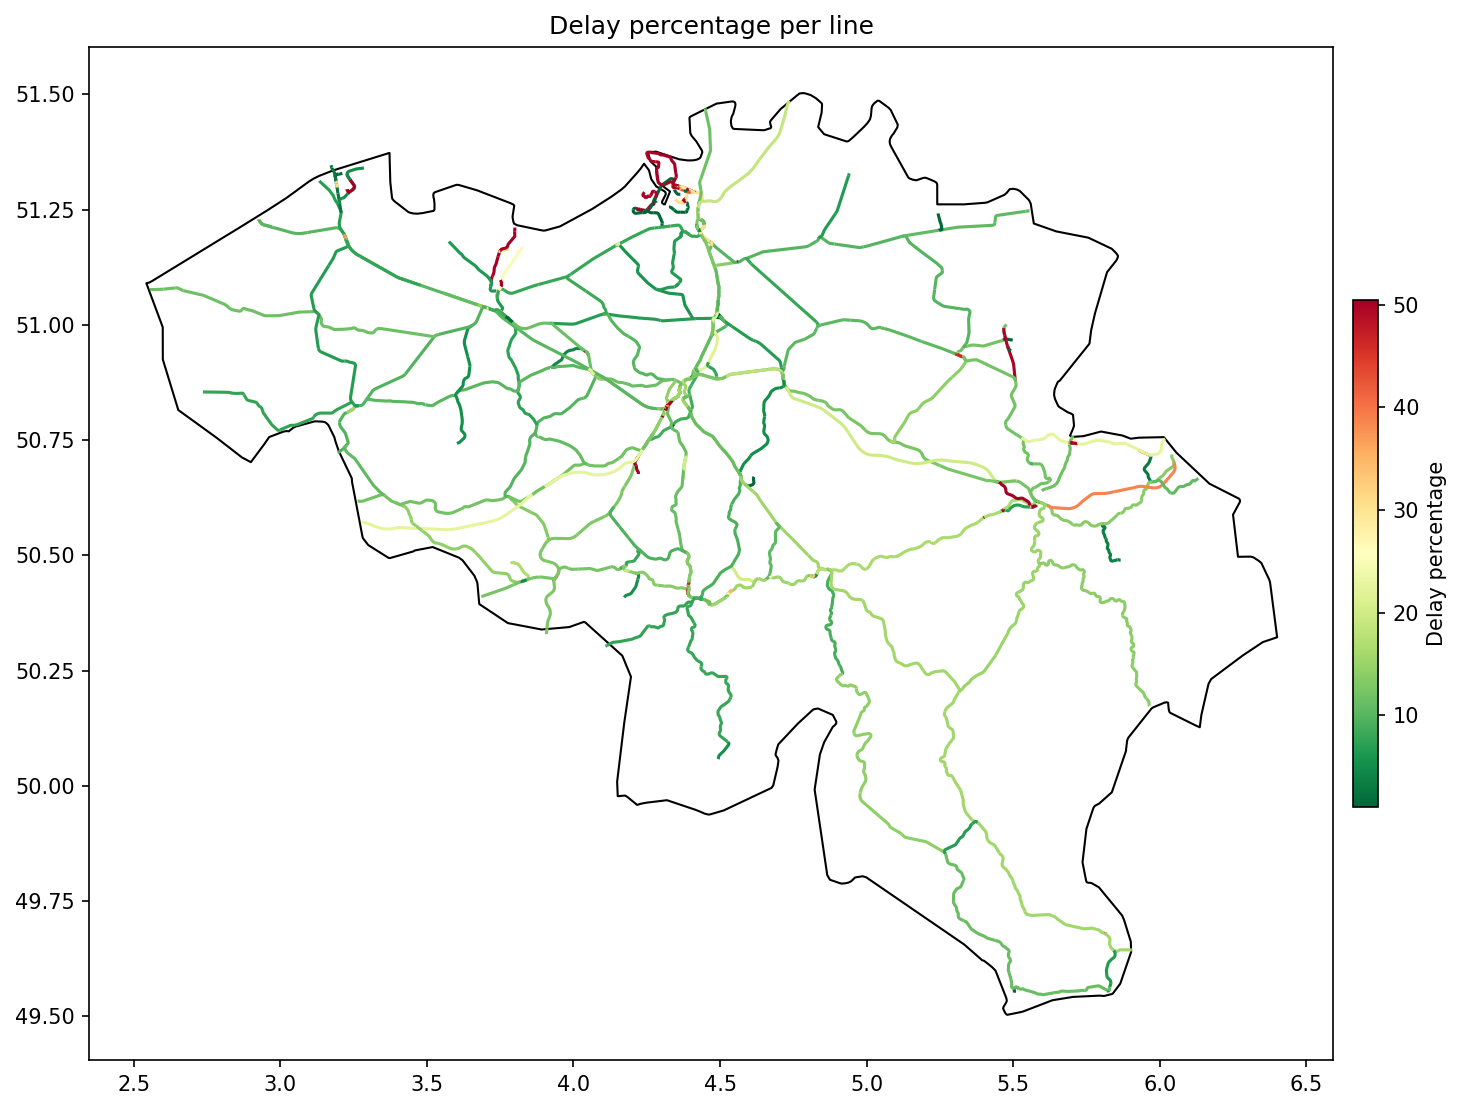

In [8]:
from matplotlib.colors import Normalize

url = (
    "https://raw.githubusercontent.com/leakyMirror/"
    "map-of-europe/master/GeoJSON/europe.geojson"
)
europe = gpd.read_file(url)

# Filter for Belgium
belgium = europe[europe["NAME"] == "Belgium"]

# plot heatmap of delay percentage per line number on the map
fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=150)
vmin, vmax = (
    delay_percentage["delay_percentage"].quantile(0.05),
    delay_percentage["delay_percentage"].quantile(0.95),
)
norm = Normalize(vmin=vmin, vmax=vmax)
delay_percentage.plot(
    ax=ax,
    column="delay_percentage",
    legend=True,
    cmap="RdYlGn_r",
    legend_kwds={
        "label": "Delay percentage",
        "shrink": 0.5,  # Reduce the size of the legend bar
        "aspect": 20,  # Make the legend bar thinner
        "pad": 0.01,  # Reduce gap between plot and legend
    },
    vmin=vmin,
    vmax=vmax,
)
belgium.plot(ax=ax, edgecolor="black", facecolor="white", linewidth=1)
plt.title("Delay percentage per line")
plt.tight_layout()
plt.show()

# Percentage of delayed trains at stations

In [9]:
analysis_query = """
WITH DelayedCounts AS (
    SELECT
        ptcar_name AS station_id,
        COUNT(*) AS total_count,
        SUM(CASE WHEN delay_arrival > 300 THEN 1 ELSE 0 END) AS delayed_count,
        (SUM(CASE WHEN delay_arrival > 300 THEN 1 ELSE 0 END) * 100.0 /
            COUNT(*)) AS delay_percentage
    FROM TRAIN_DATA
    GROUP BY ptcar_name
    HAVING COUNT(*) >= 100
)
SELECT
    s.id,
    s.name,
    s.geom,
    dc.total_count,
    dc.delayed_count,
    dc.delay_percentage
FROM DelayedCounts dc
JOIN STATIONS s ON dc.station_id = s.id
ORDER BY dc.delay_percentage DESC;
"""

delayed_stations = gpd.read_postgis(analysis_query, engine)

delayed_stations

,id,name,geom,total_count,delayed_count,delay_percentage
0,764,VORST-RIJTUIGEN-DIENSTPERRON,POINT (4.31464 50.81765),848,591,69.693396
1,337,HASSELT-L.C.I.,POINT (5.30975 50.9369),371,244,65.768194
2,585,OOSTENDE-BUNDEL B,POINT (2.93927 51.21781),167,108,64.670659
3,537,MONCEAU-RECEPTION,POINT (4.39166 50.43599),104,62,59.615385
4,767,VORST-ZUID-SPOREN 920/926,POINT (4.31084 50.81102),1487,723,48.621385
...,...,...,...,...,...,...
713,635,RONSE,POINT (3.60261 50.74237),131960,3791,2.872840
714,701,SPA-GERONSTERE,POINT (5.86623 50.48928),119413,3249,2.720809
715,800,ZEEBRUGGE-DORP,POINT (3.19684 51.32659),72246,1940,2.685270
716,814,Zwankendamme,POINT (3.19694 51.31001),30974,696,2.247046


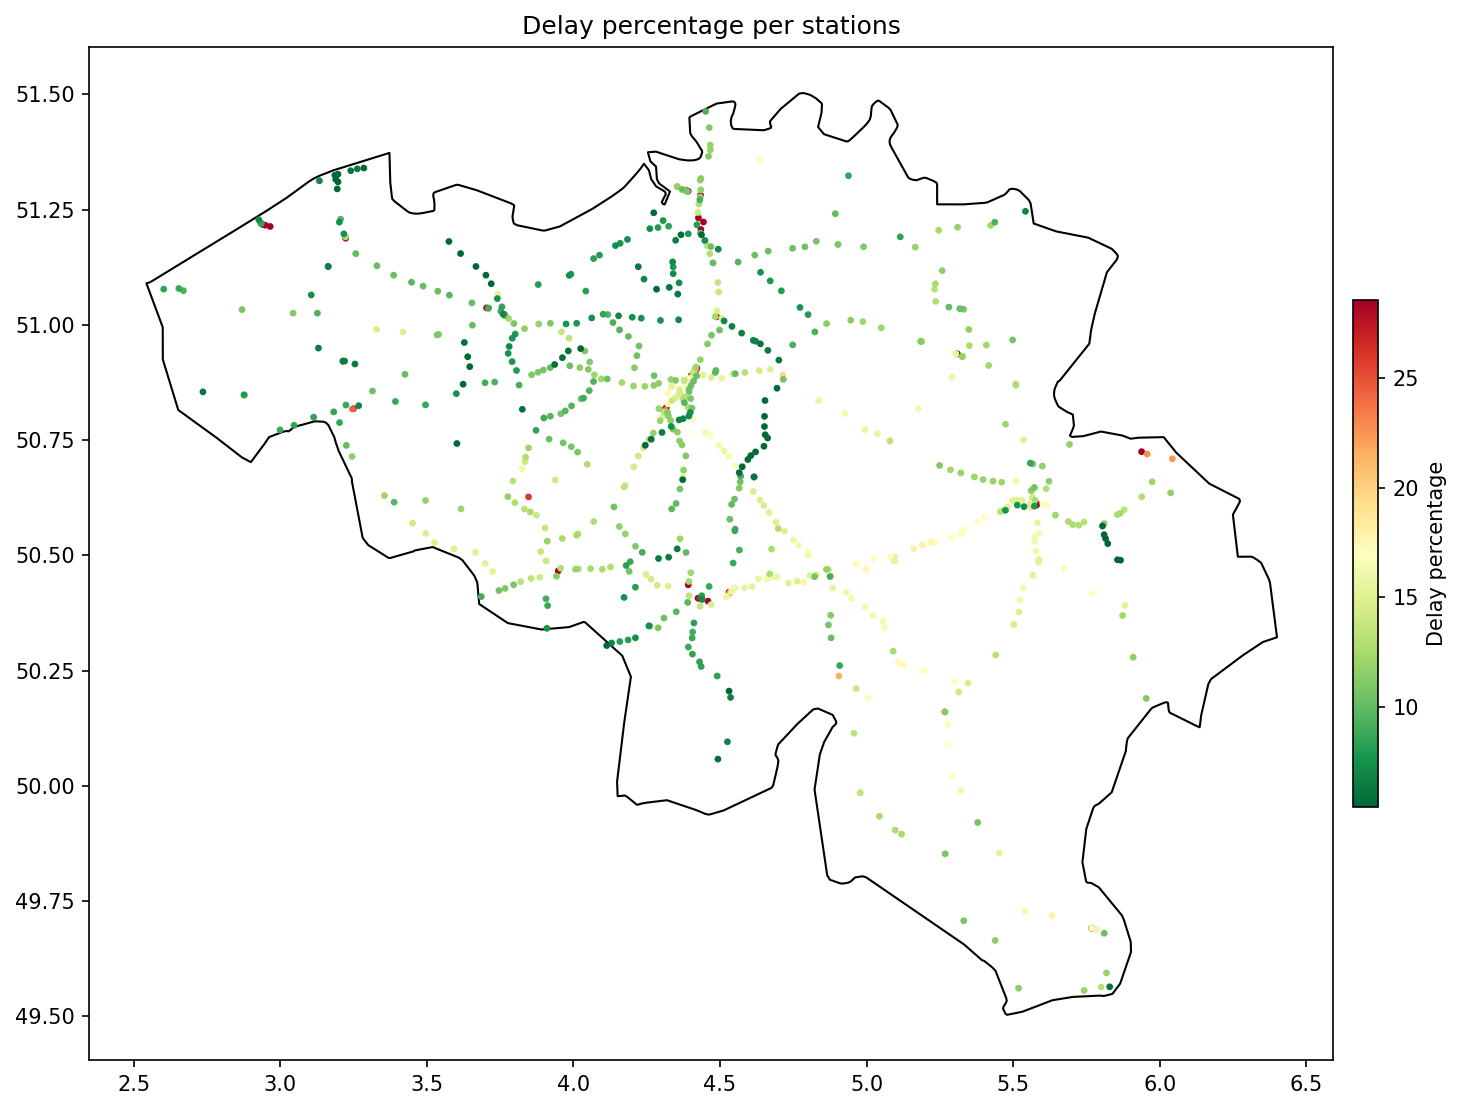

In [10]:
url = (
    "https://raw.githubusercontent.com/leakyMirror/"
    "map-of-europe/master/GeoJSON/europe.geojson"
)
europe = gpd.read_file(url)

# Filter for Belgium
belgium = europe[europe["NAME"] == "Belgium"]

fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=150)
vmin, vmax = (
    delayed_stations["delay_percentage"].quantile(0.05),
    delayed_stations["delay_percentage"].quantile(0.95),
)
norm = Normalize(vmin=vmin, vmax=vmax)
belgium.plot(ax=ax, edgecolor="black", facecolor="white", linewidth=1)
delayed_stations.plot(
    ax=ax,
    column="delay_percentage",
    legend=True,
    cmap="RdYlGn_r",
    legend_kwds={
        "label": "Delay percentage",
        "shrink": 0.5,  # Reduce the size of the legend bar
        "aspect": 20,  # Make the legend bar thinner
        "pad": 0.01,  # Reduce gap between plot and legend
    },
    vmin=vmin,
    vmax=vmax,
    markersize=5,
)
plt.title("Delay percentage per stations")
plt.tight_layout()
plt.show()

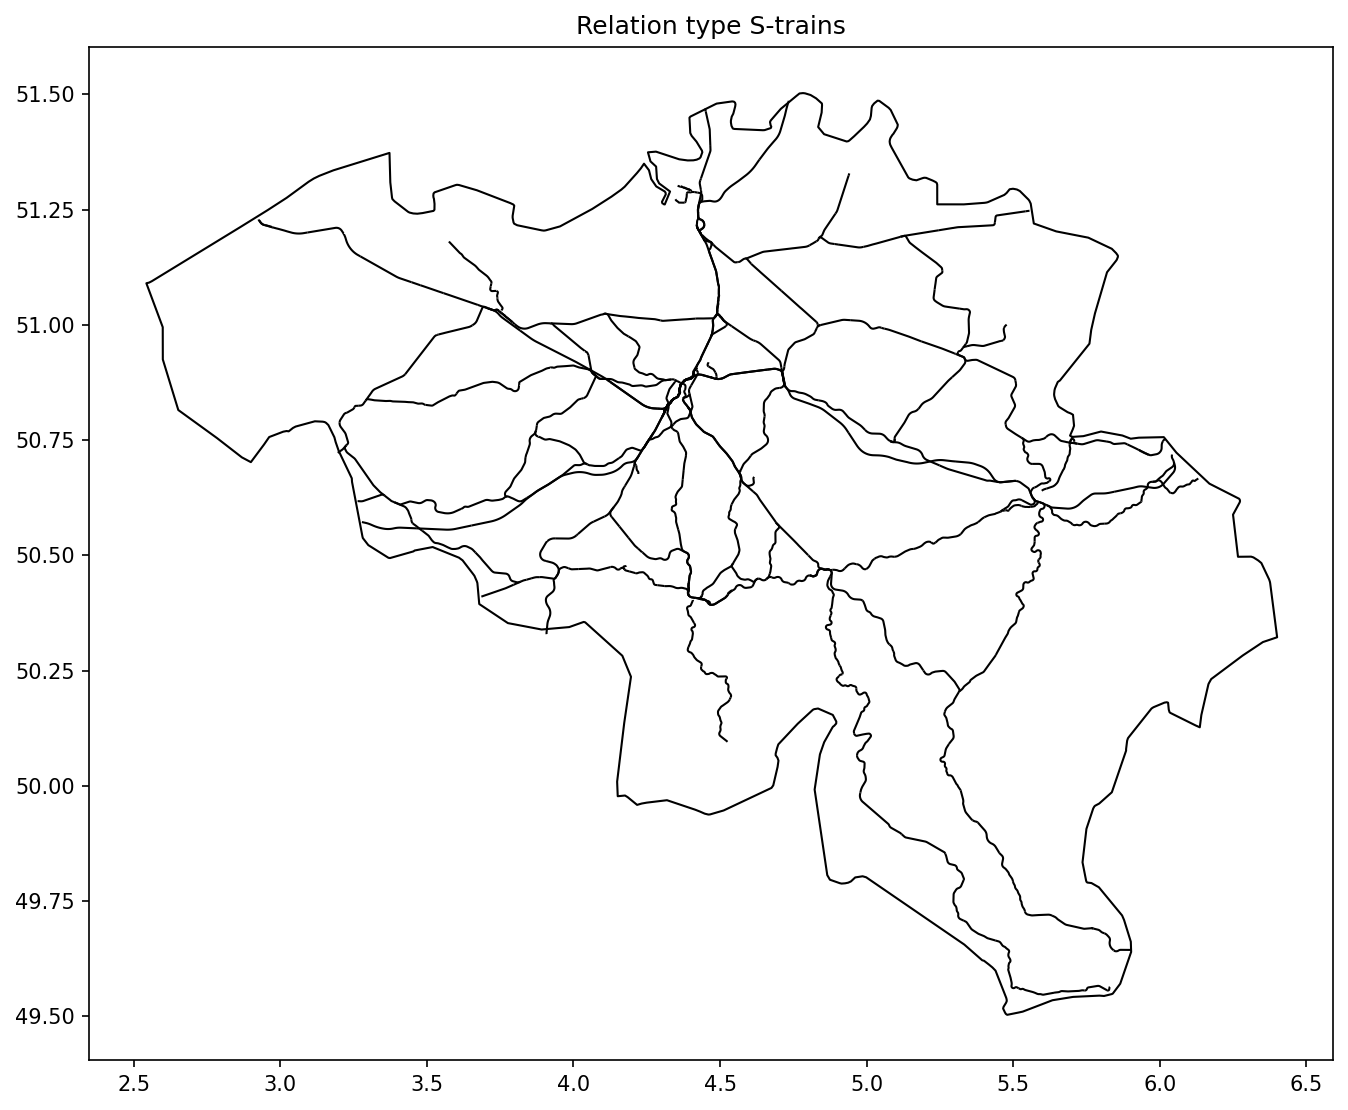

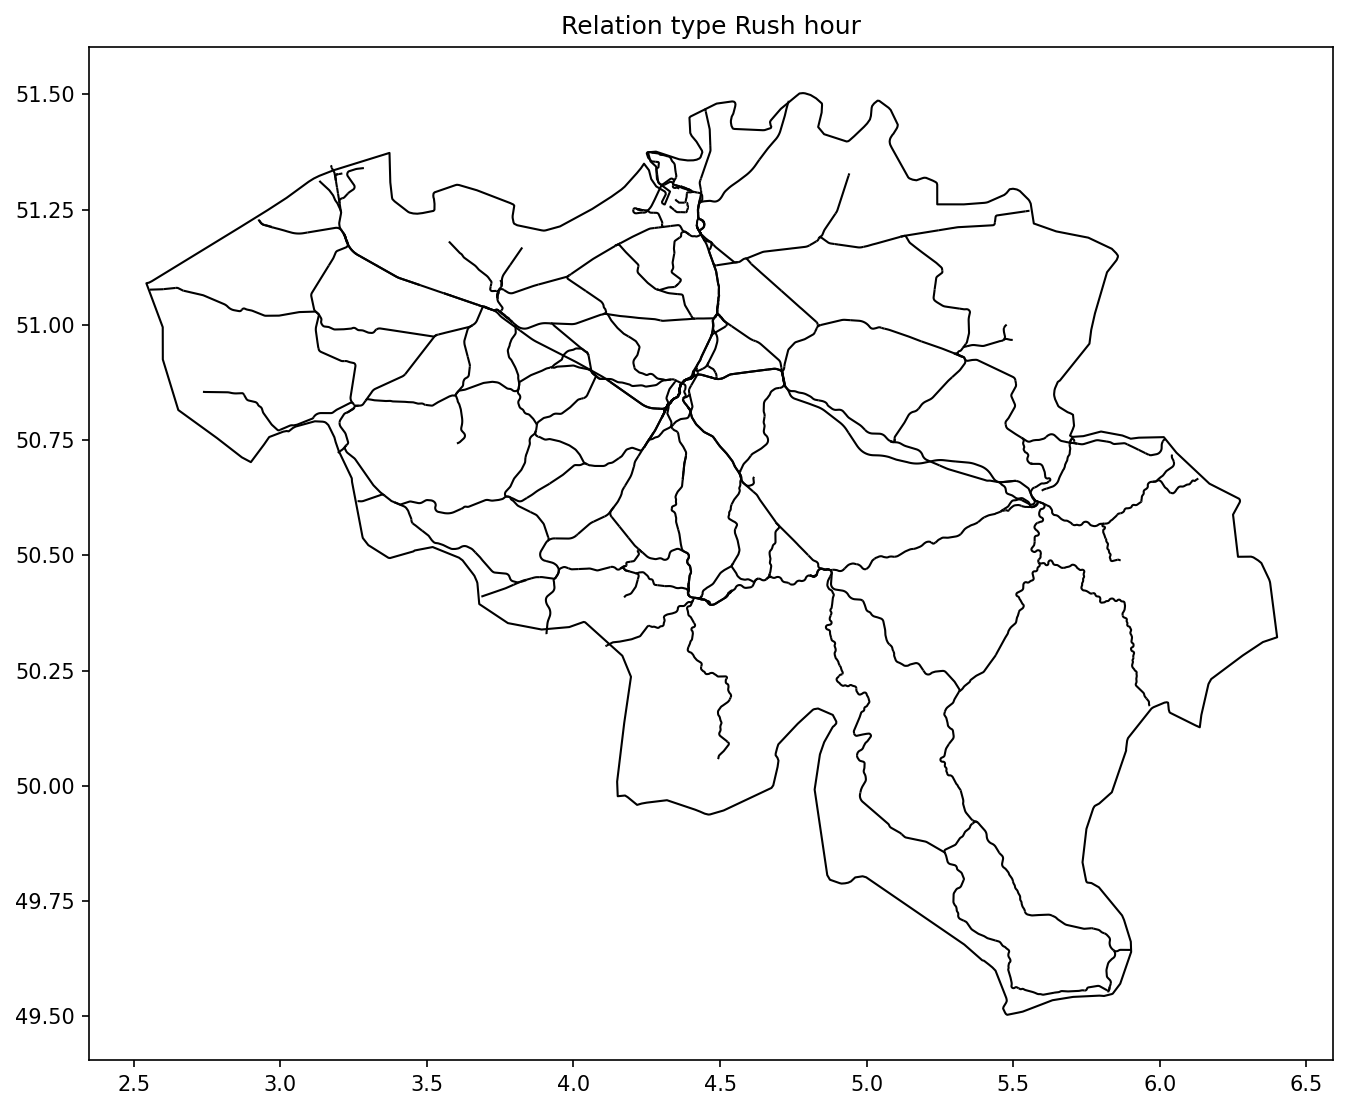

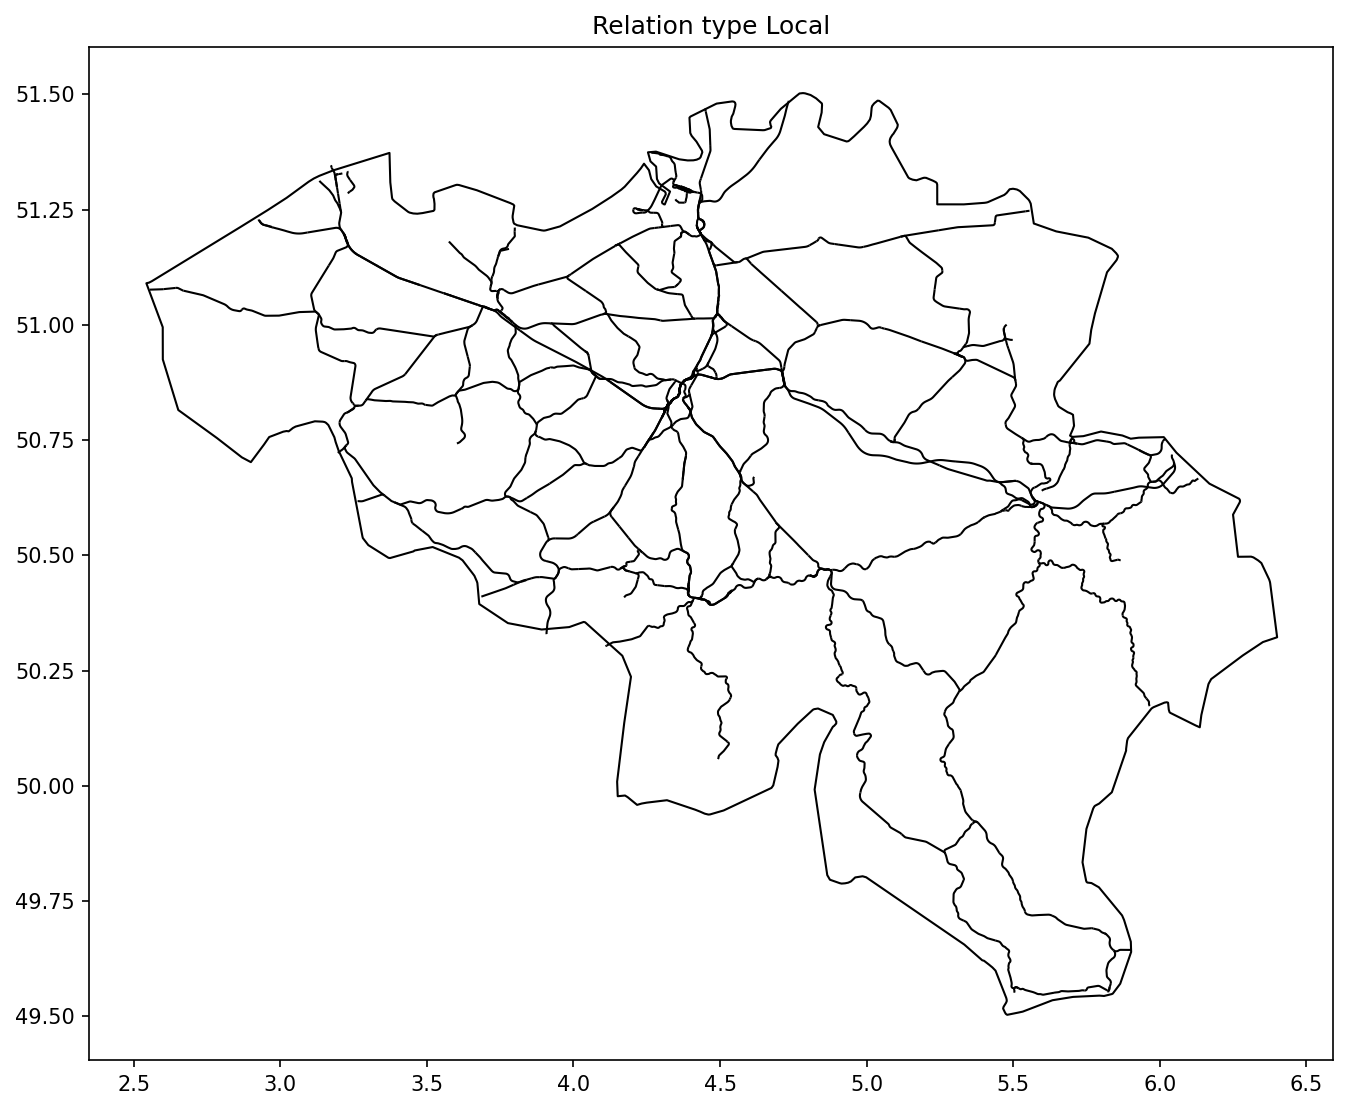

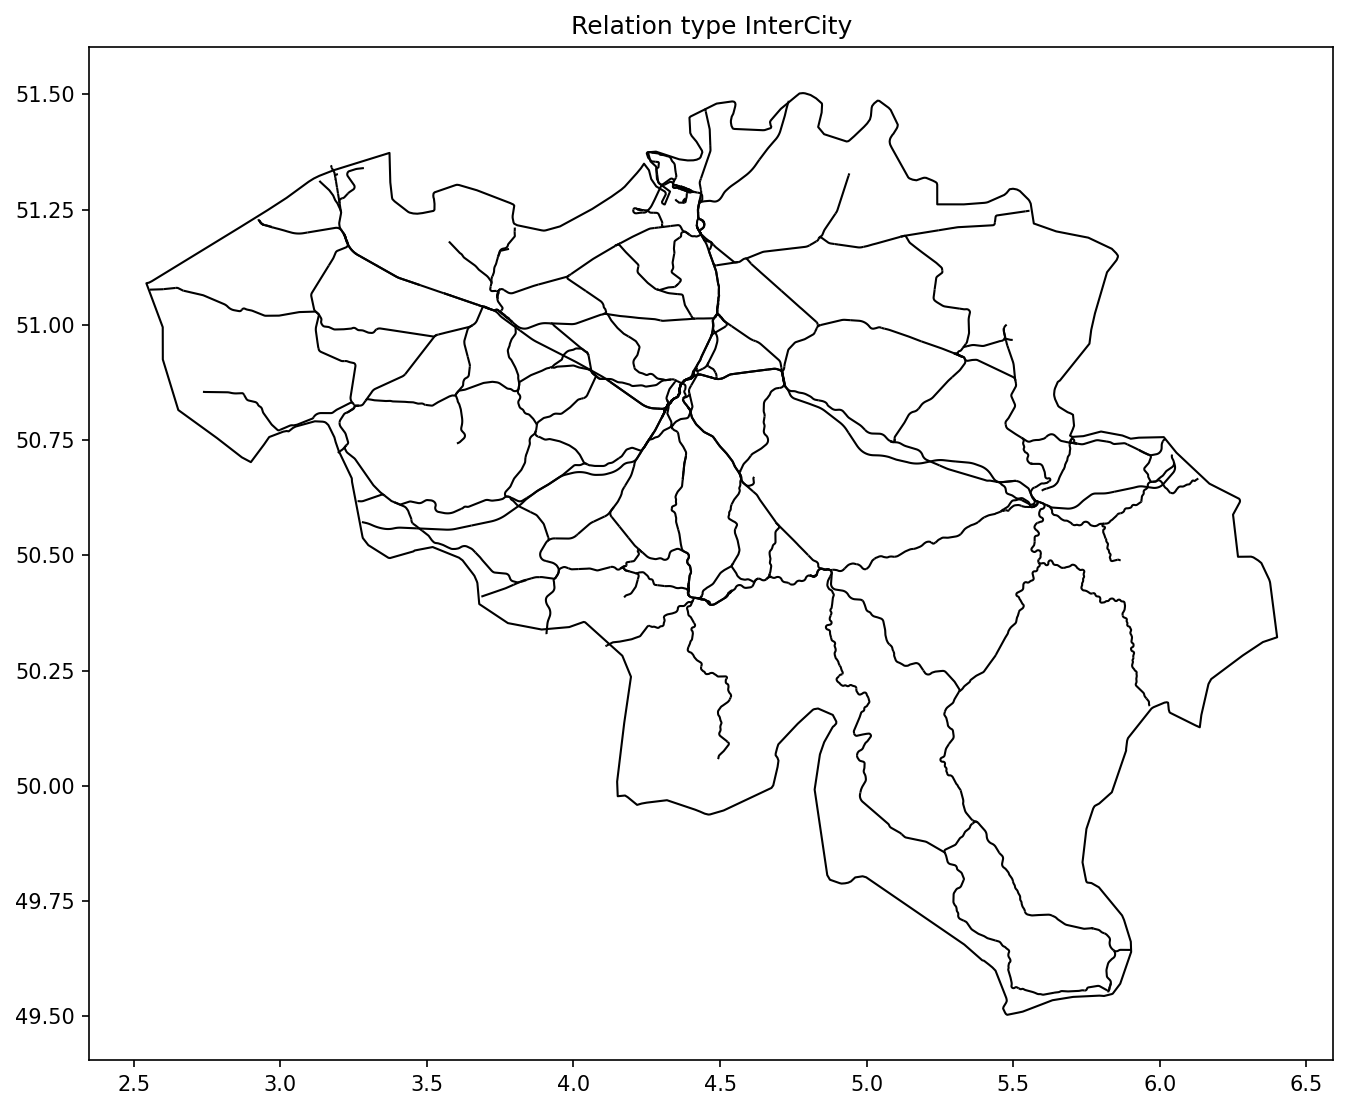

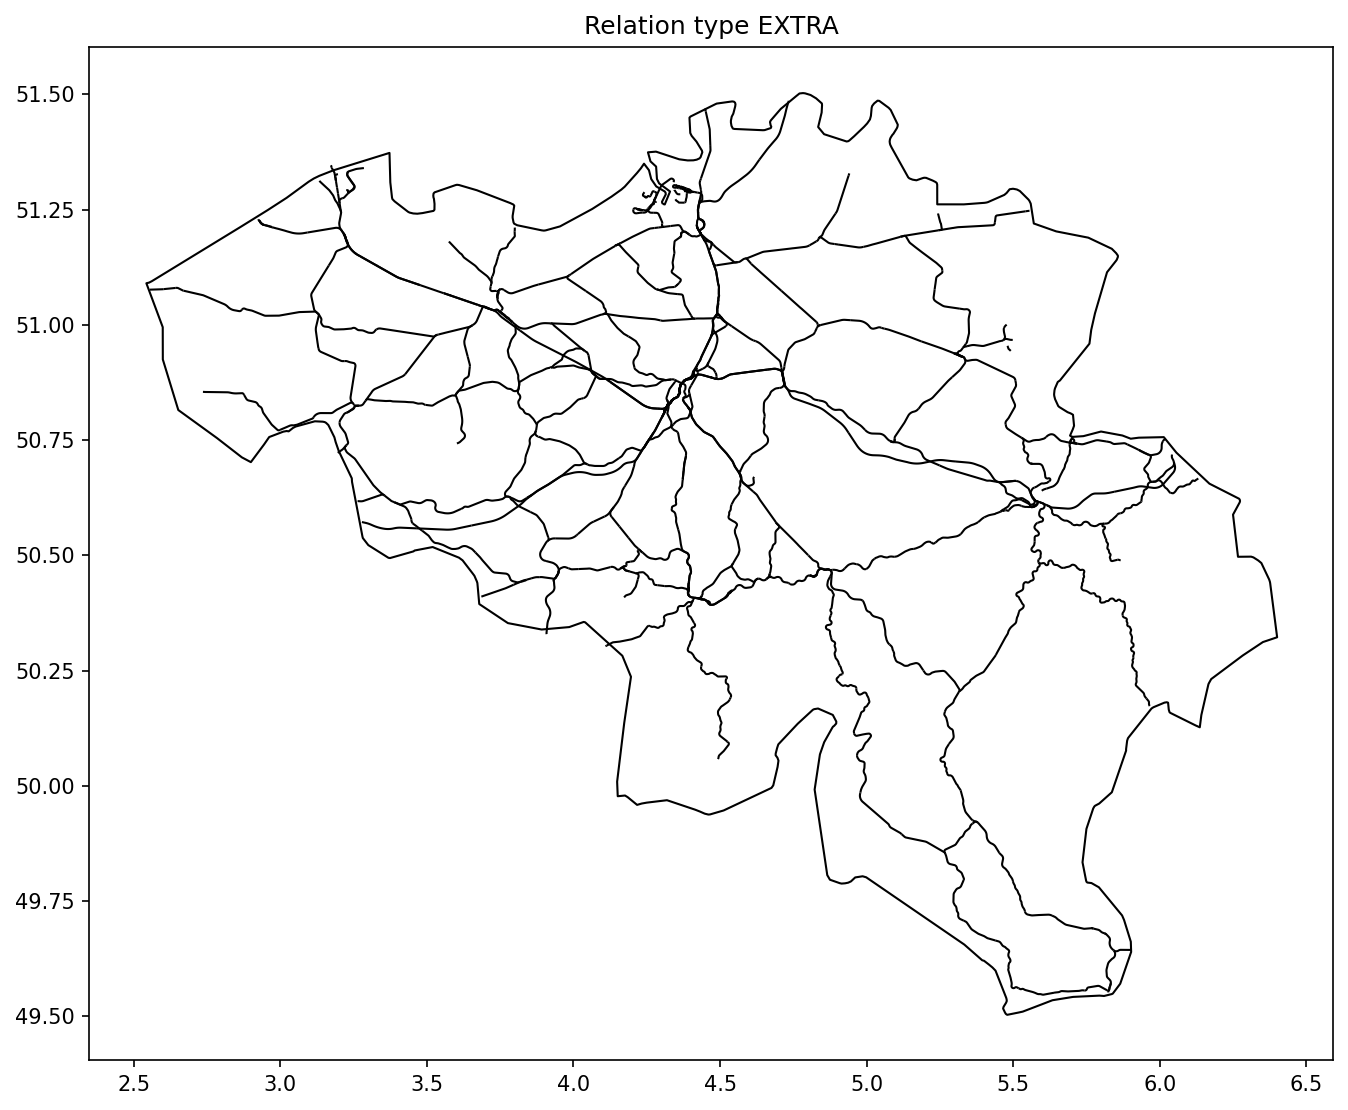

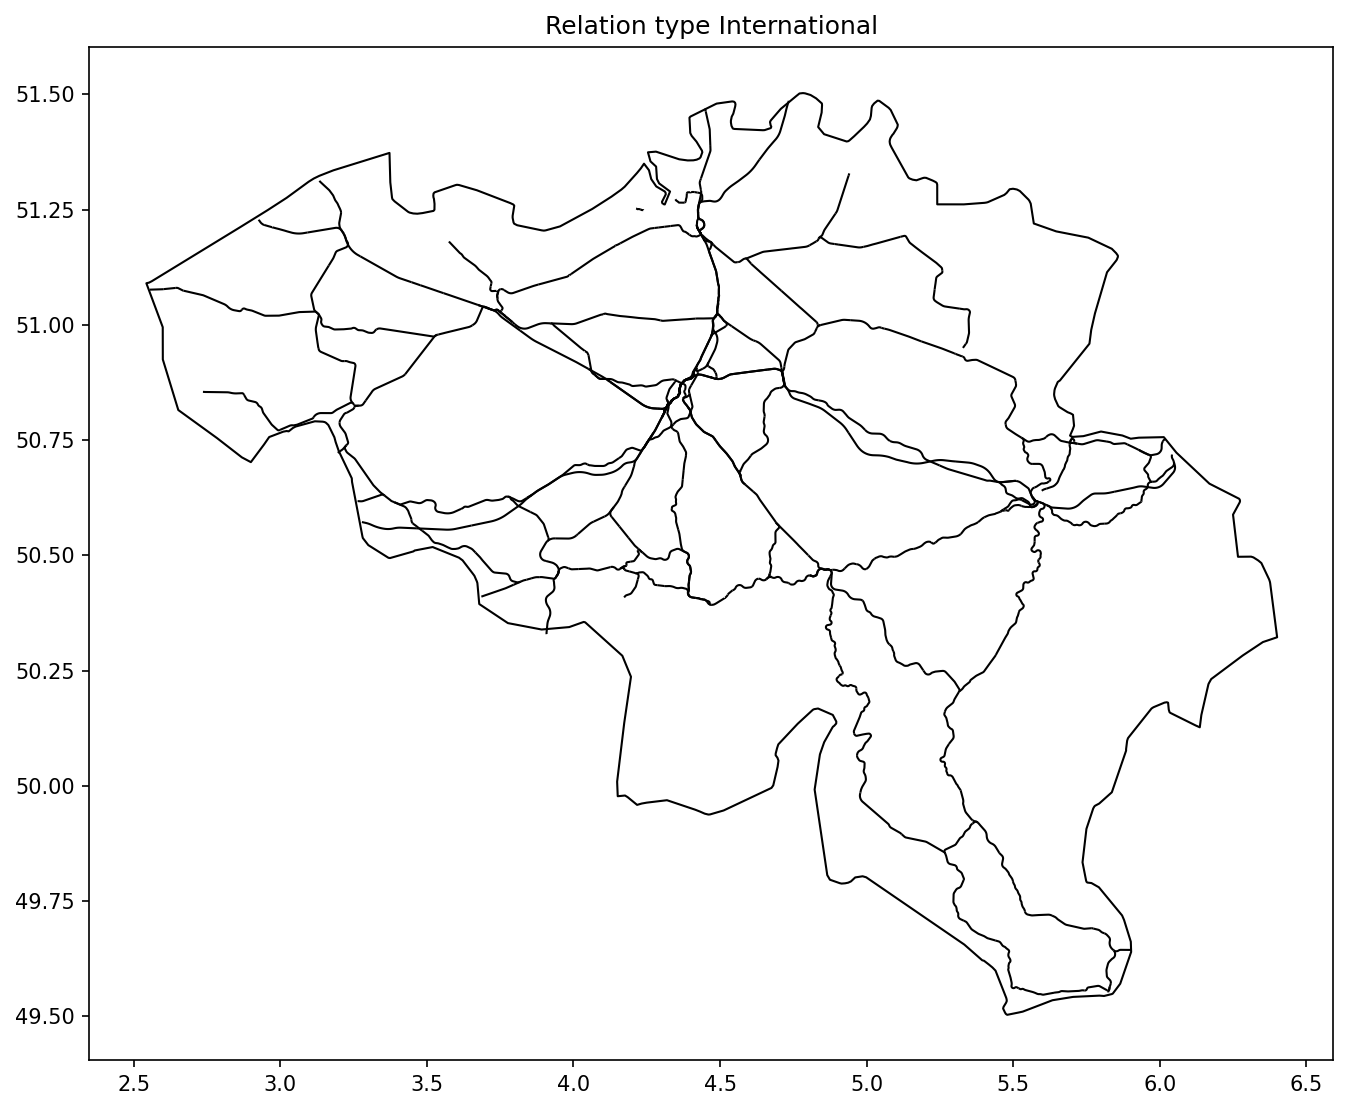

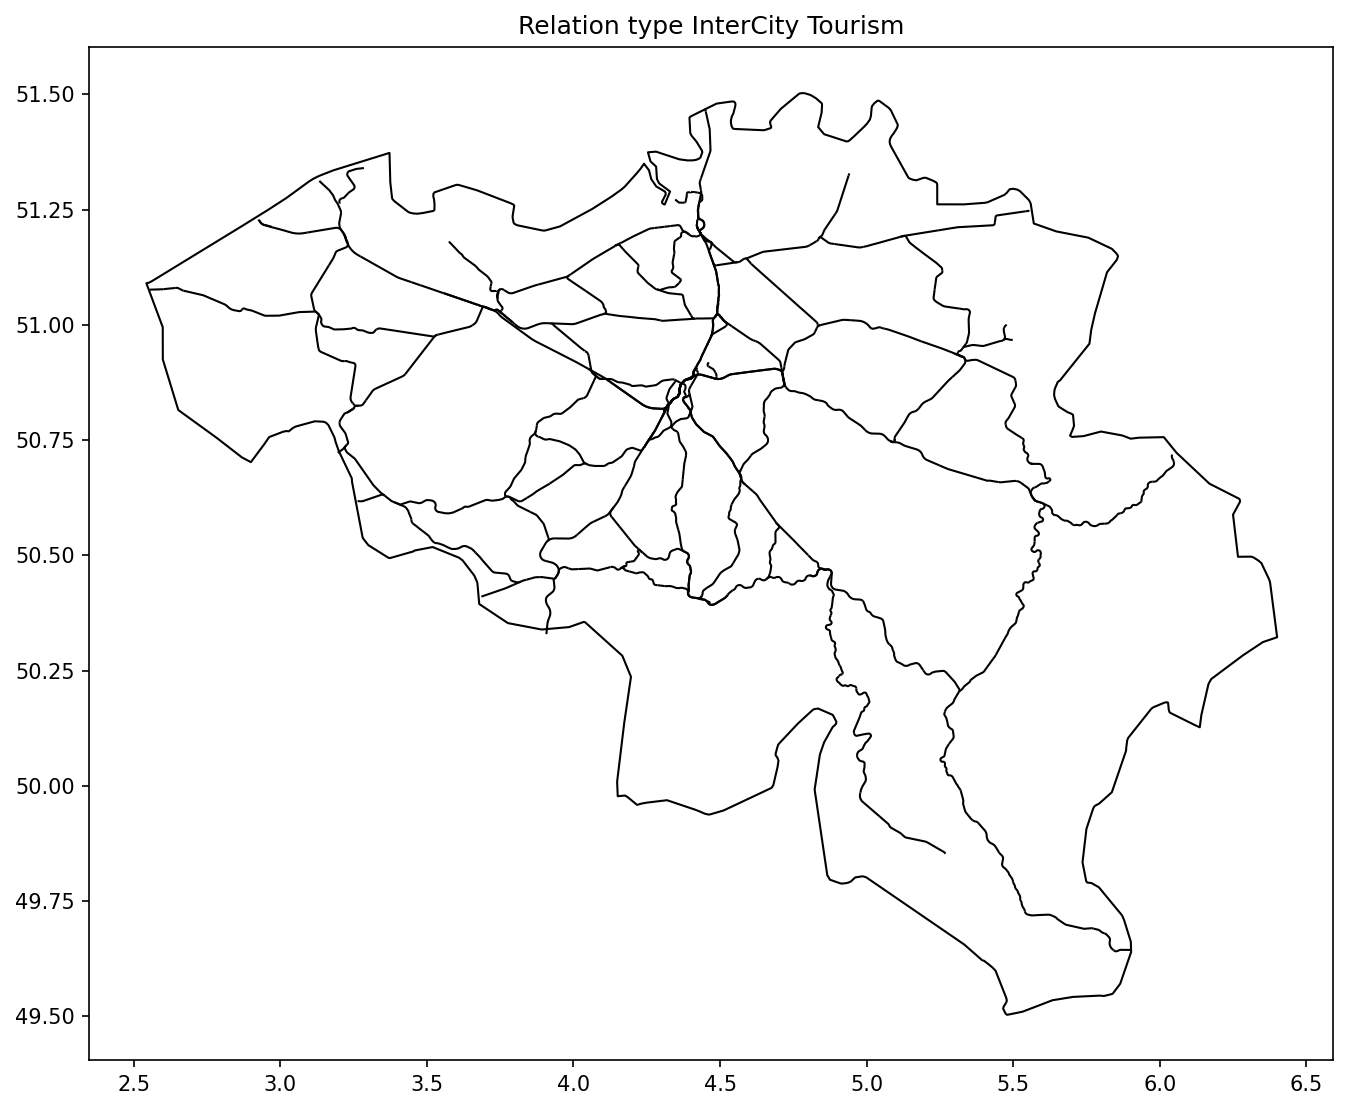

In [11]:
type_map = {
    0: "Cannot be determined",
    1: "S-trains",
    2: "Rush hour",
    3: "Local",
    4: "InterCity",
    5: "EXTRA",
    6: "International",
    7: "InterCity Tourism",
}


url = (
    "https://raw.githubusercontent.com/leakyMirror/"
    "map-of-europe/master/GeoJSON/europe.geojson"
)
europe = gpd.read_file(url)

# Filter for Belgium
belgium = europe[europe["NAME"] == "Belgium"]

for i in range(1, 8):
    summary_query = f"""
    WITH lines AS (
        SELECT DISTINCT
            td.line_number_departure
        FROM
            train_data td
        JOIN
            relation rel on rel.id = td.relation
        WHERE
            rel.type = '{i}'
            AND td.line_number_departure is not null
    )
    SELECT DISTINCT
        l.line_number_departure ,
        r.geom
    FROM
        lines l
    JOIN
        railway r on r.line_number = l.line_number_departure
    """

    line_relation = gpd.read_postgis(summary_query, engine)

    fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=150)
    line_relation.plot(ax=ax, color="black", linewidth=1)
    belgium.plot(ax=ax, edgecolor="black", facecolor="white", linewidth=1)
    plt.title(f"Relation type {type_map[i]}")
    plt.tight_layout()
    plt.show()

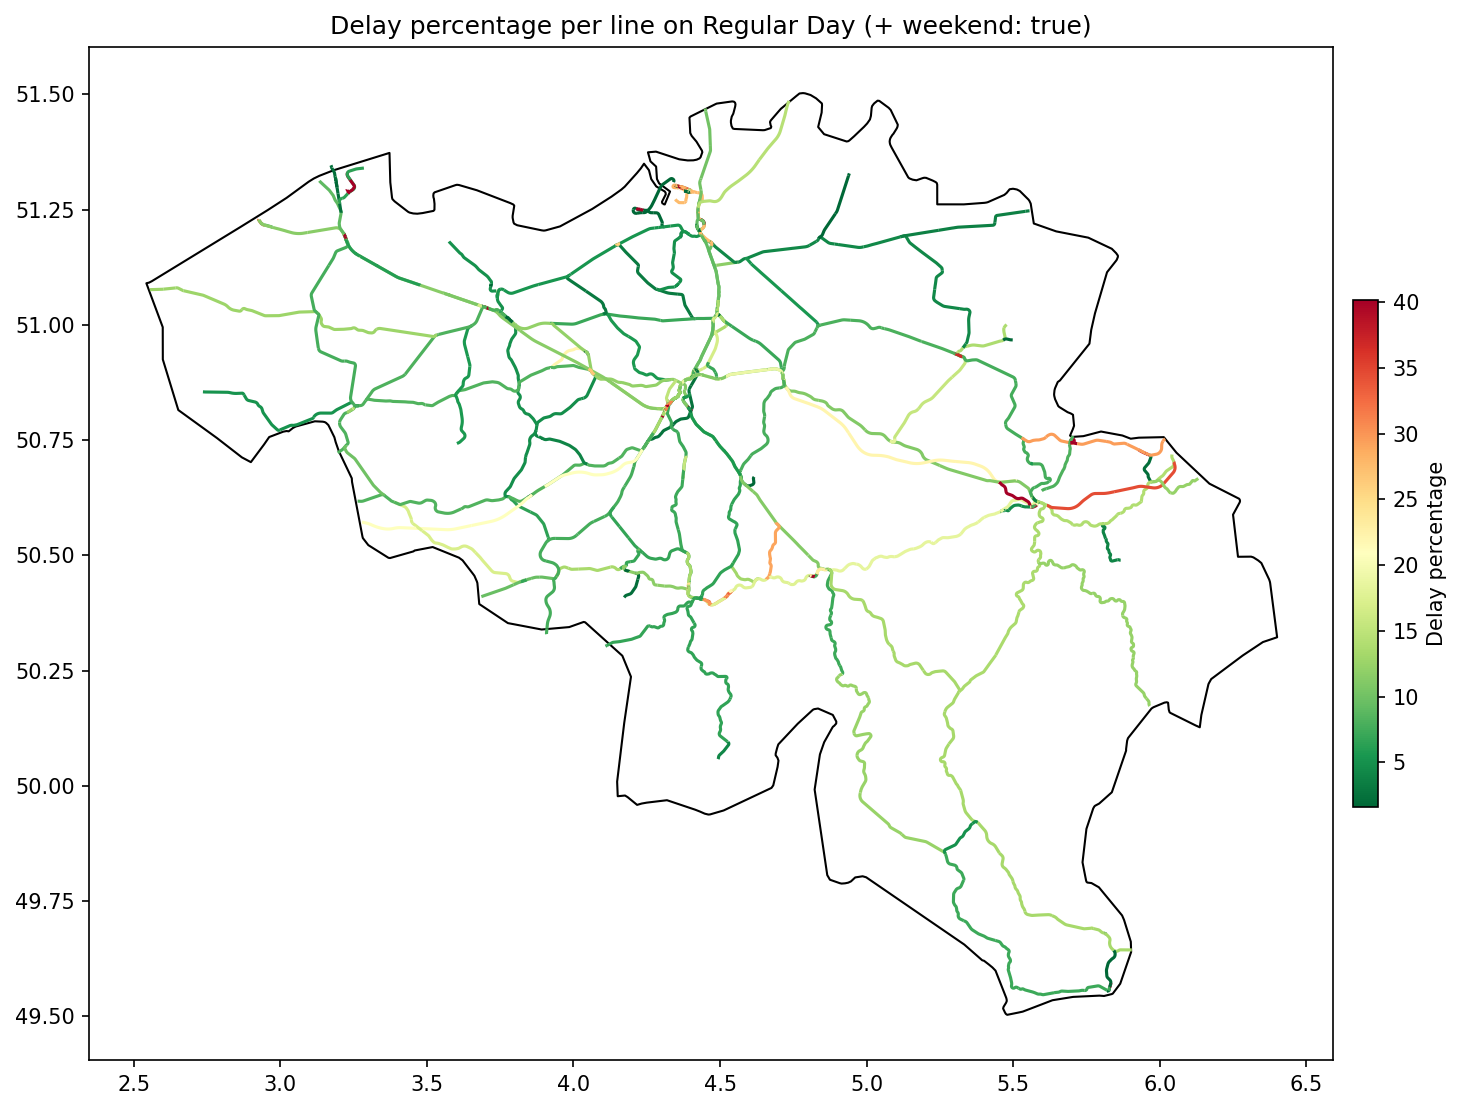

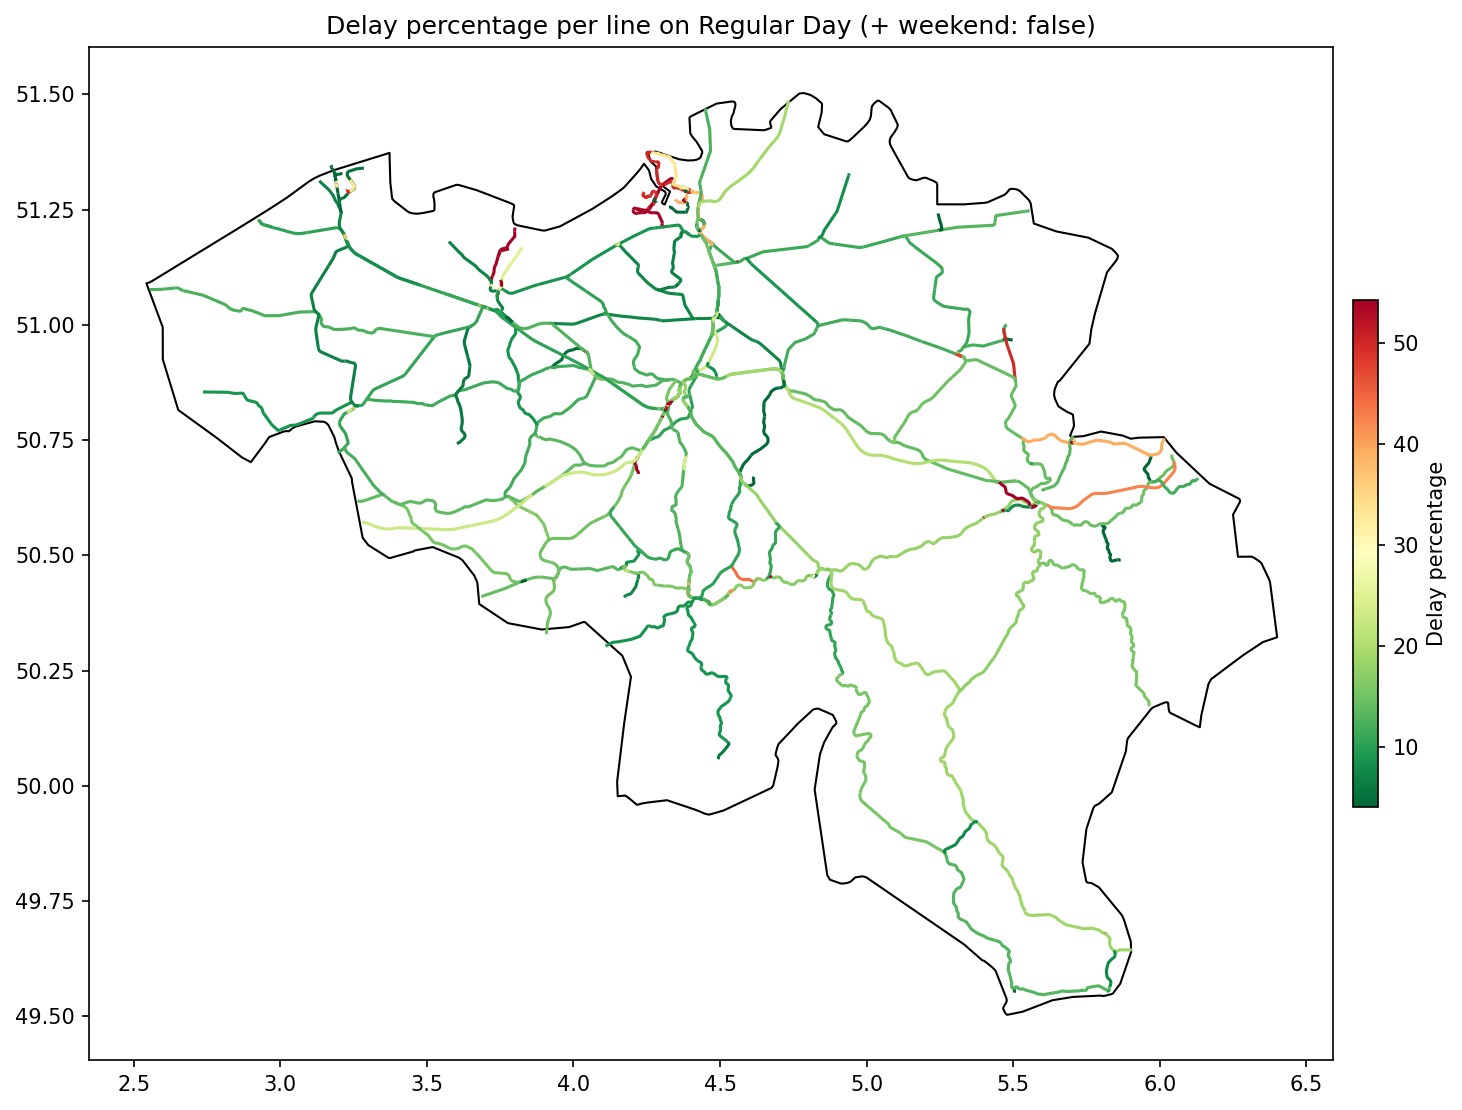

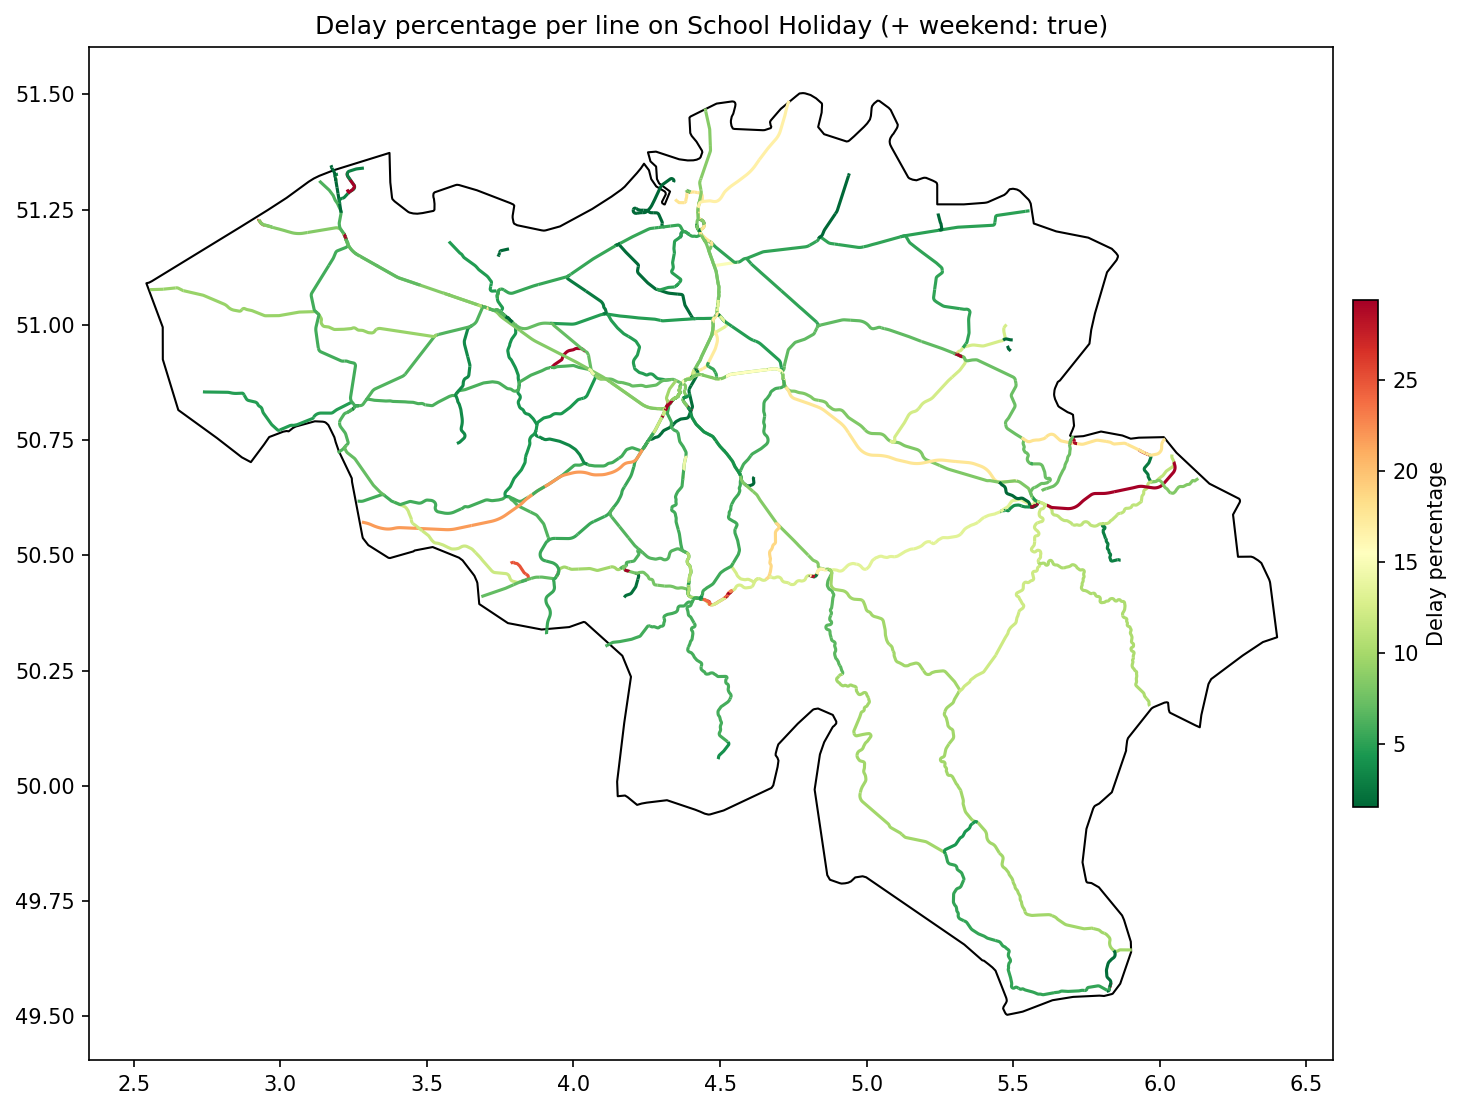

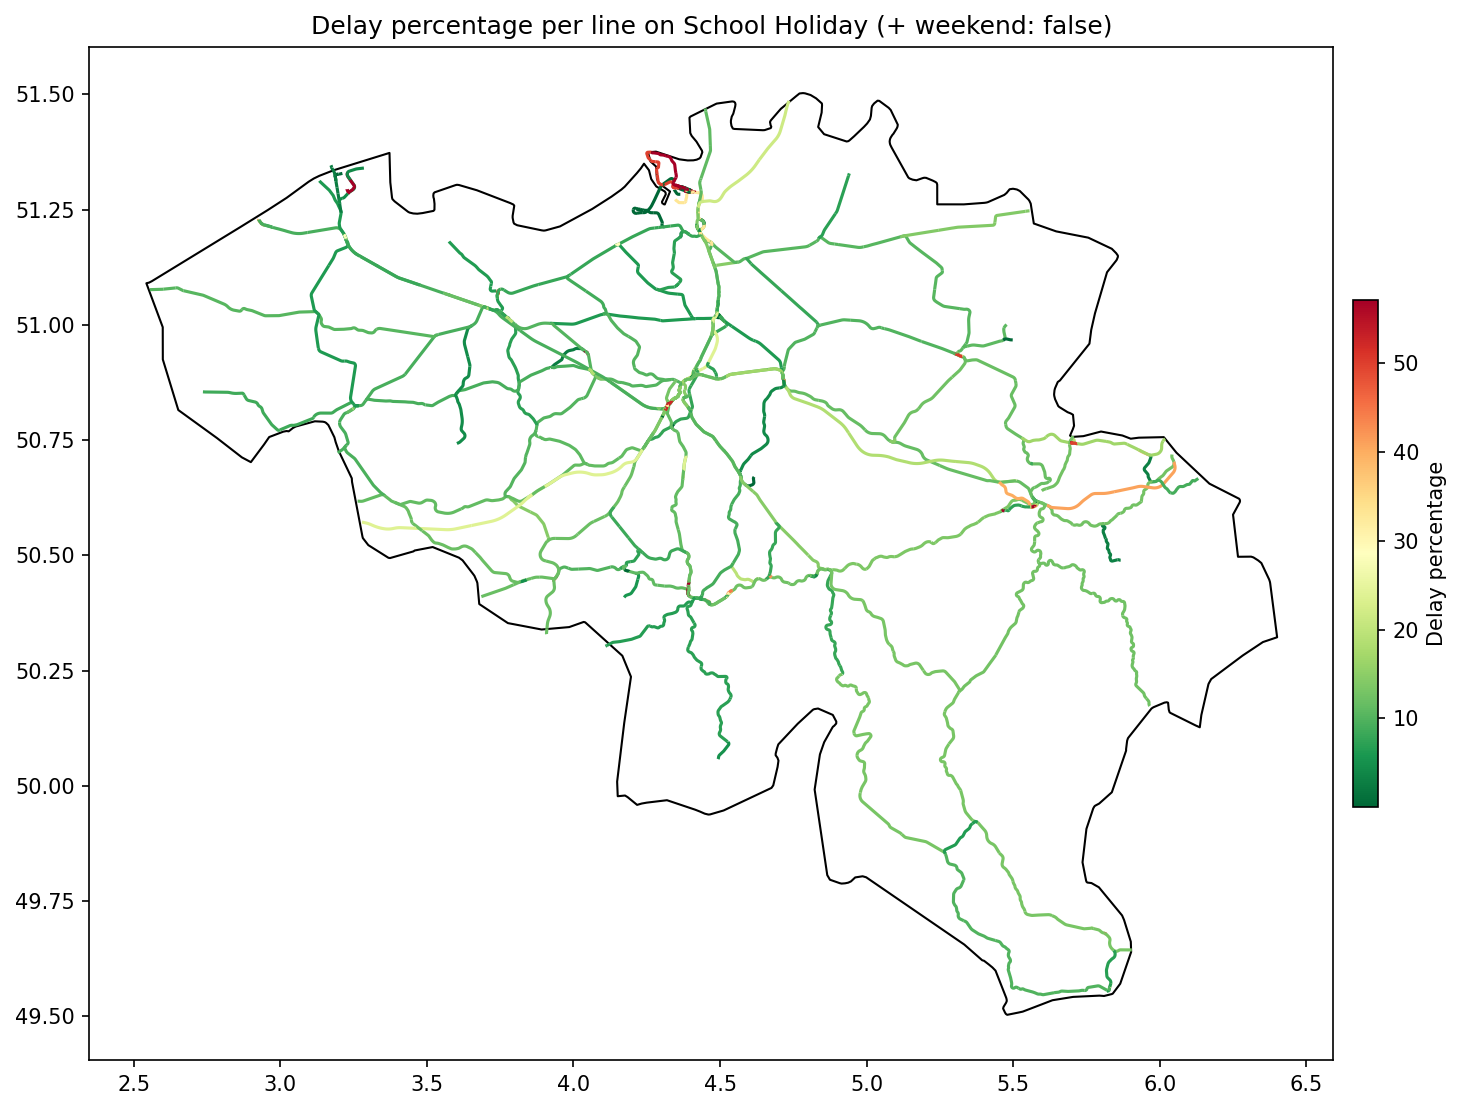

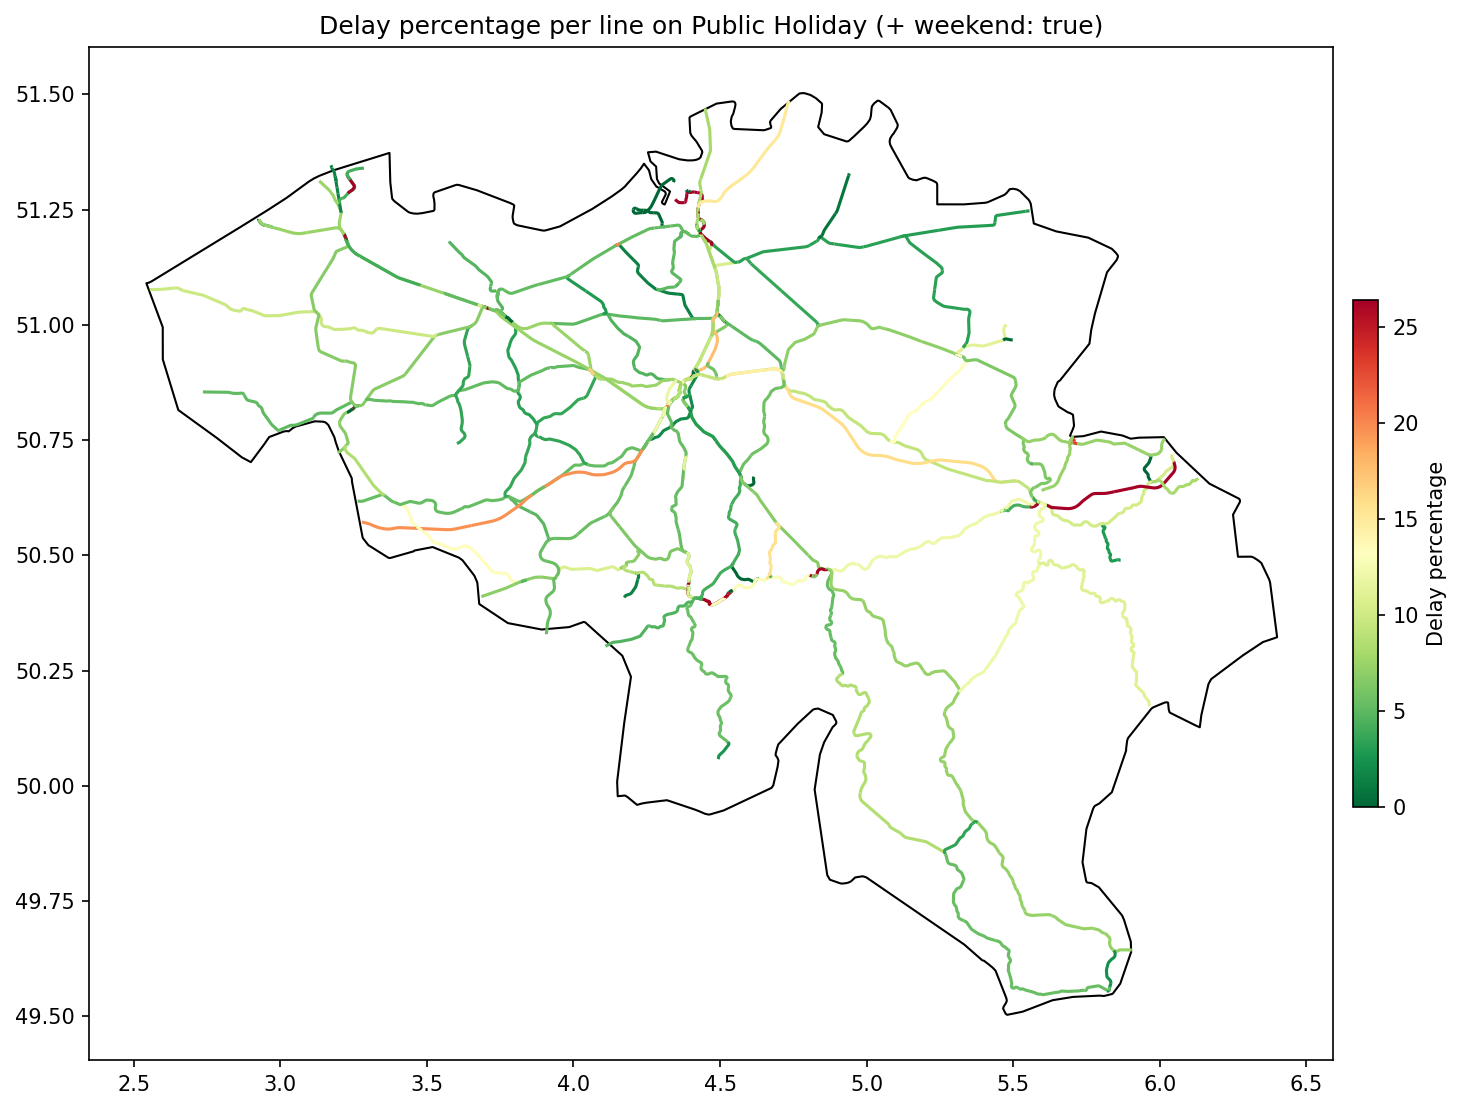

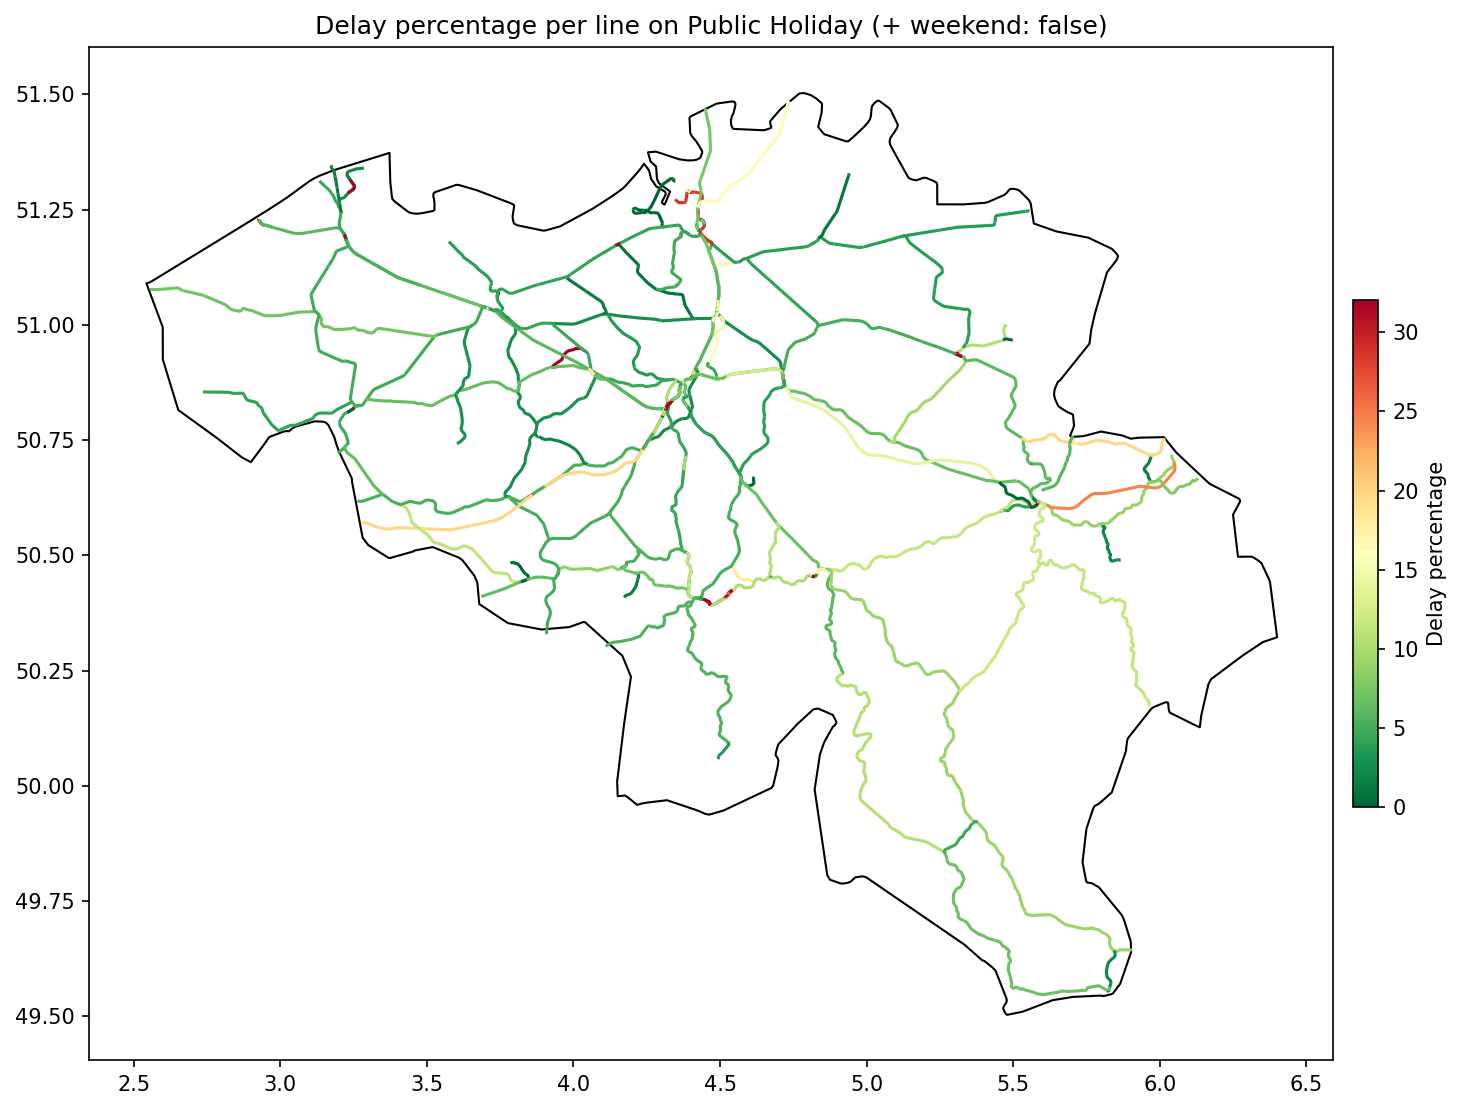

In [12]:
type_day_map = {0: "Regular Day", 1: "School Holiday", 2: "Public Holiday"}

for i in range(0, 3):
    for is_weekend in ["true", "false"]:
        query = f"""
        WITH delay_counts AS (
            SELECT
                line_number_departure,
                COUNT(*) as TOTAL_COUNT,
                SUM(CASE WHEN delay_arrival > 300 THEN 1 ELSE 0 END) AS
                    delayed_count,
                (SUM(CASE WHEN delay_arrival > 300 THEN 1 ELSE 0 END) *
                    100.0 / COUNT(*)) AS delay_percentage
            FROM
                train_data td
            JOIN
                type_day h on h.date = td.departure_date
            WHERE
                h.holiday = '{i}'
                AND h.weekend = {is_weekend}
            GROUP BY
                line_number_departure
        )
        SELECT
            cd.line_number_departure,
            cd.delay_percentage,
            r.geom
        FROM
            delay_counts cd
        JOIN
            railway r ON cd.line_number_departure = r.line_number
        """

        delay_percentage = gpd.read_postgis(query, engine)

        fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=150)
        vmin, vmax = (
            delay_percentage["delay_percentage"].quantile(0.05),
            delay_percentage["delay_percentage"].quantile(0.95),
        )
        norm = Normalize(vmin=vmin, vmax=vmax)
        delay_percentage.plot(
            ax=ax,
            column="delay_percentage",
            legend=True,
            cmap="RdYlGn_r",
            legend_kwds={
                "label": "Delay percentage",
                "shrink": 0.5,  # Reduce the size of the legend bar
                "aspect": 20,  # Make the legend bar thinner
                "pad": 0.01,  # Reduce gap between plot and legend
            },
            vmin=vmin,
            vmax=vmax,
        )
        belgium.plot(ax=ax, edgecolor="black", facecolor="white", linewidth=1)
        plt.title(
            f"Delay percentage per line on {type_day_map[i]} "
            f"(+ weekend: {is_weekend})"
        )
        plt.tight_layout()
        plt.show()

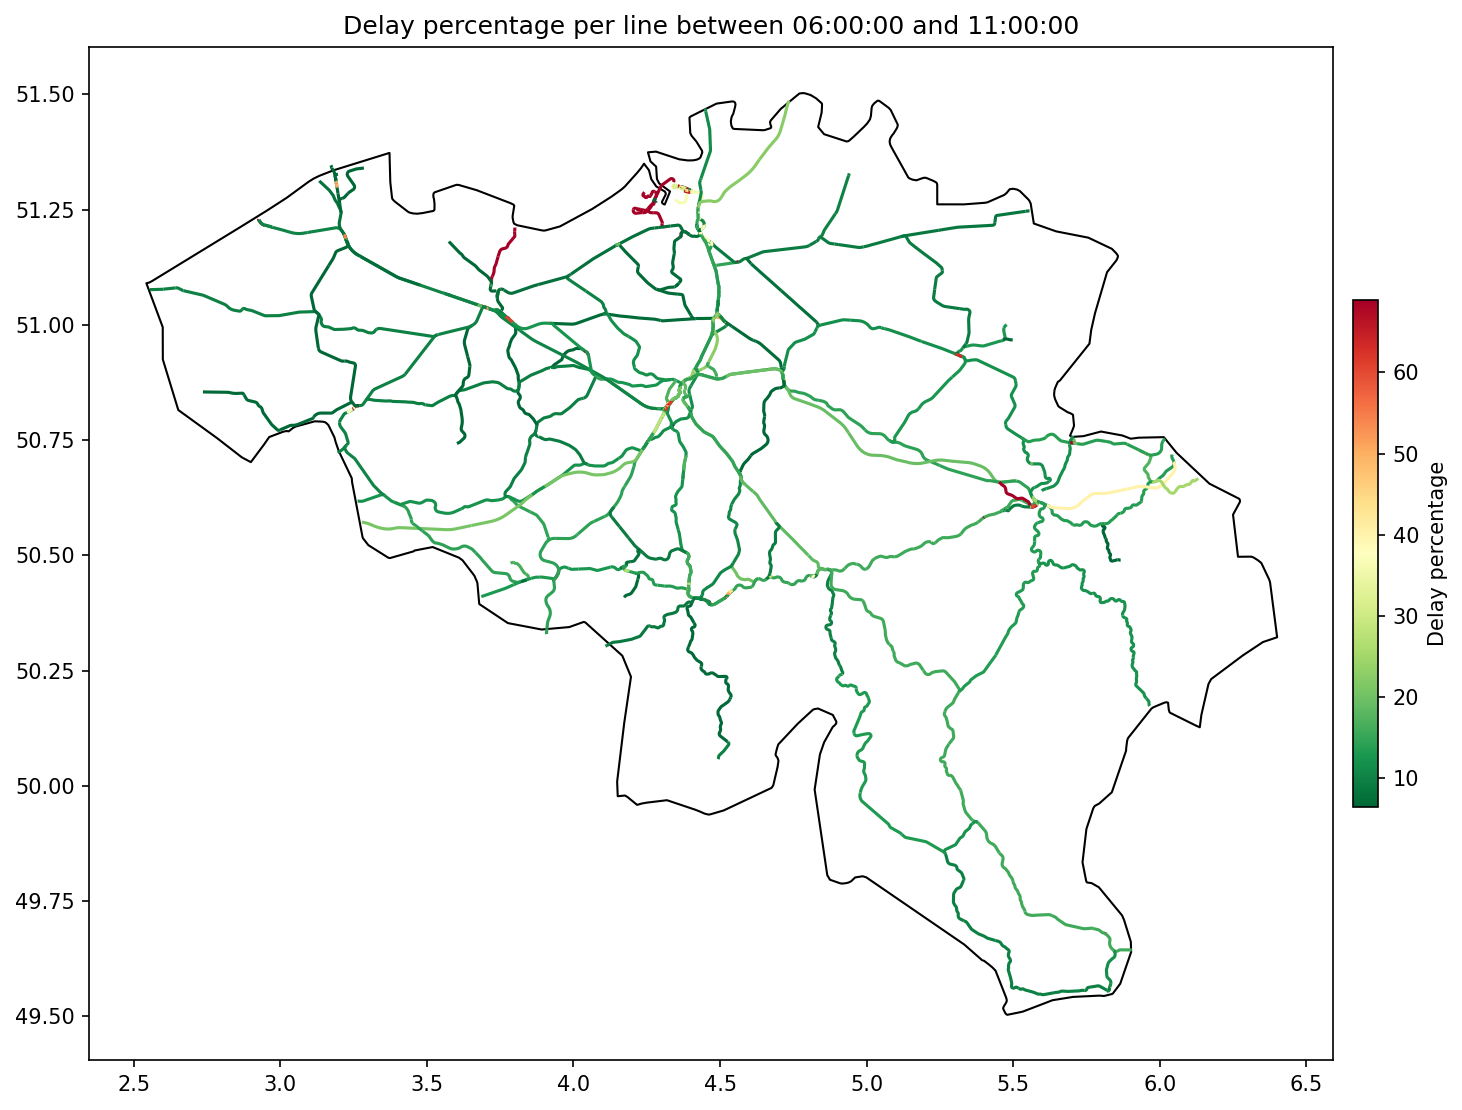

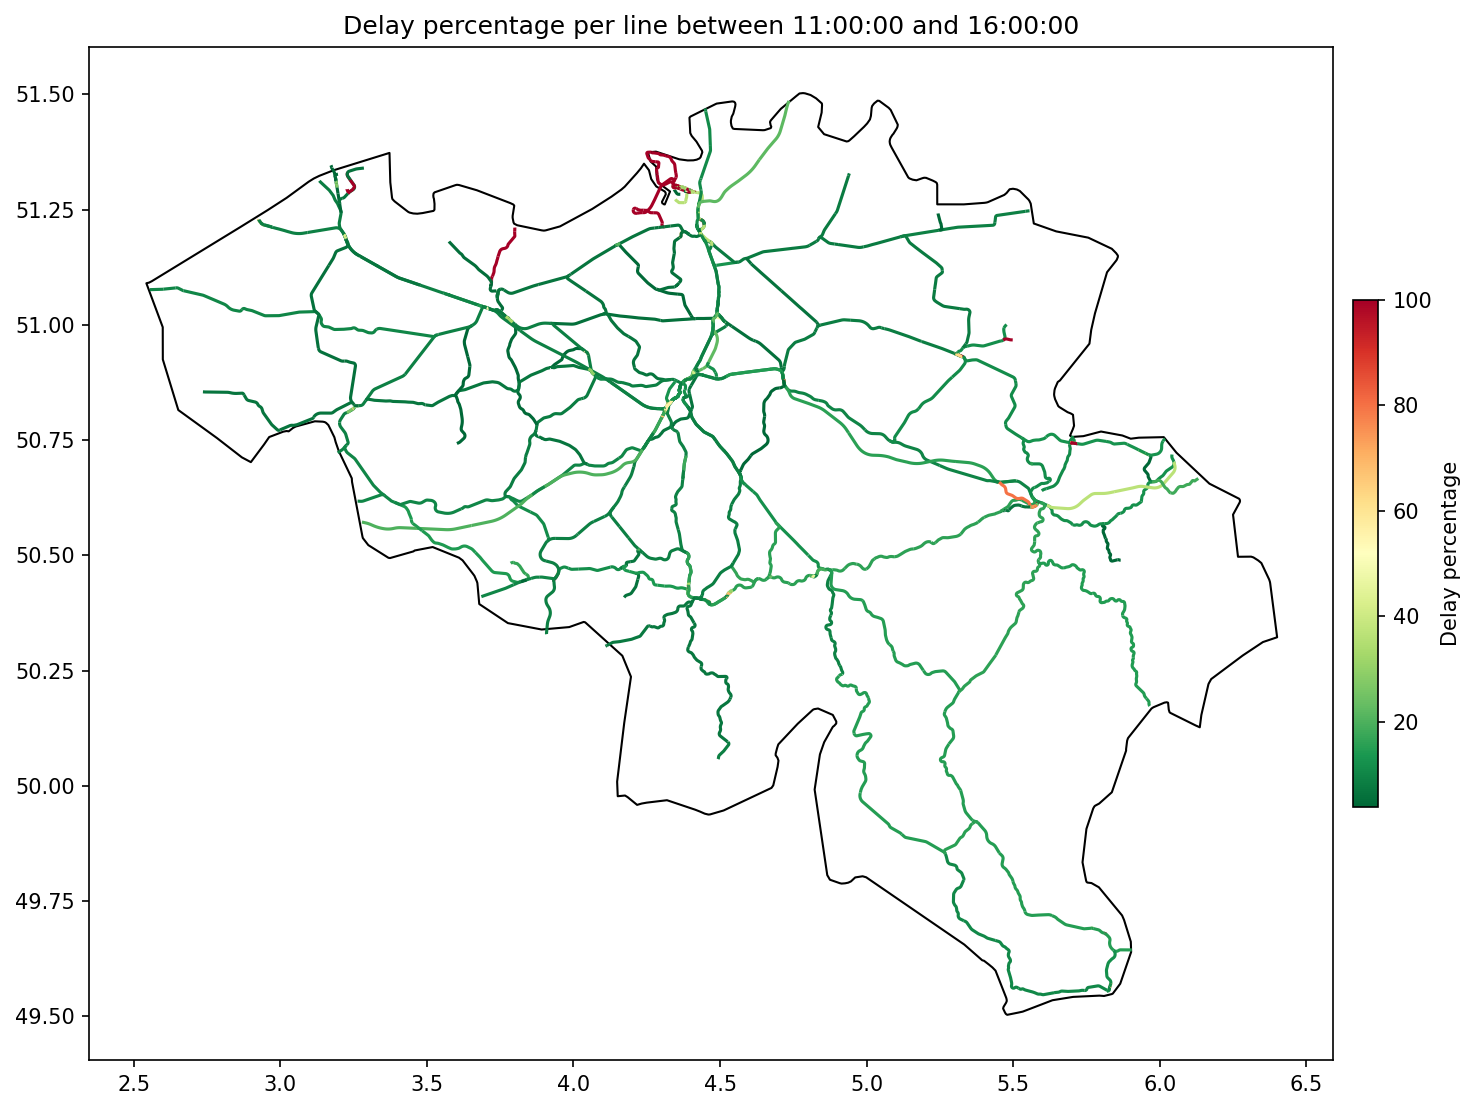

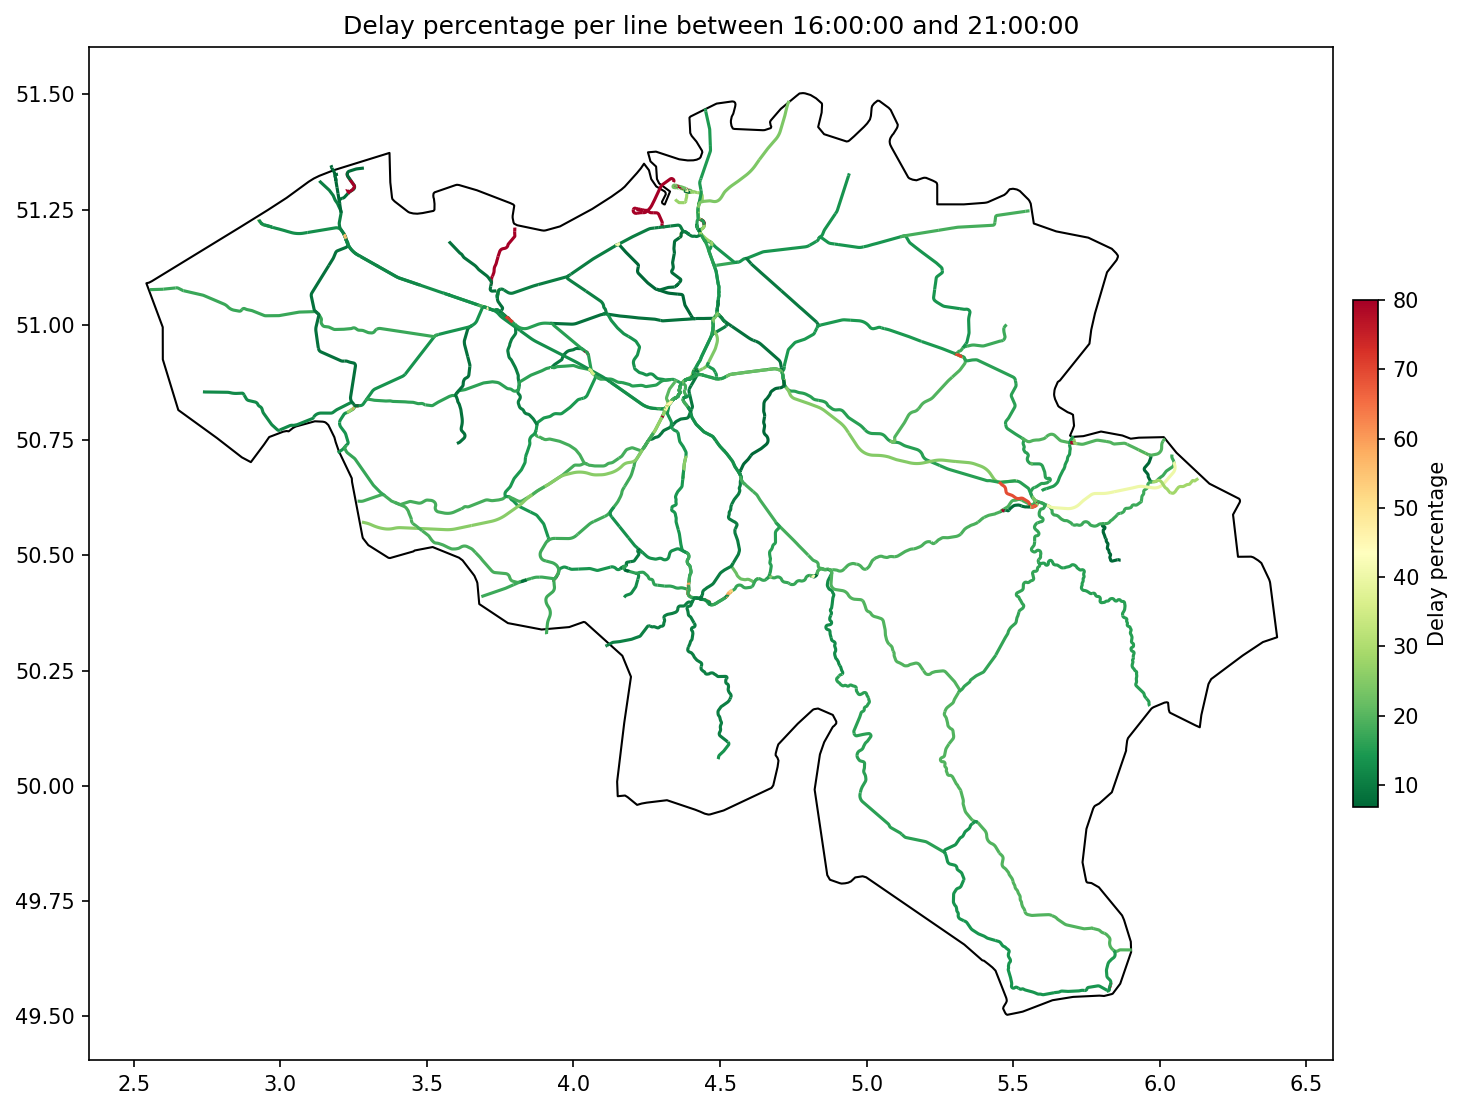

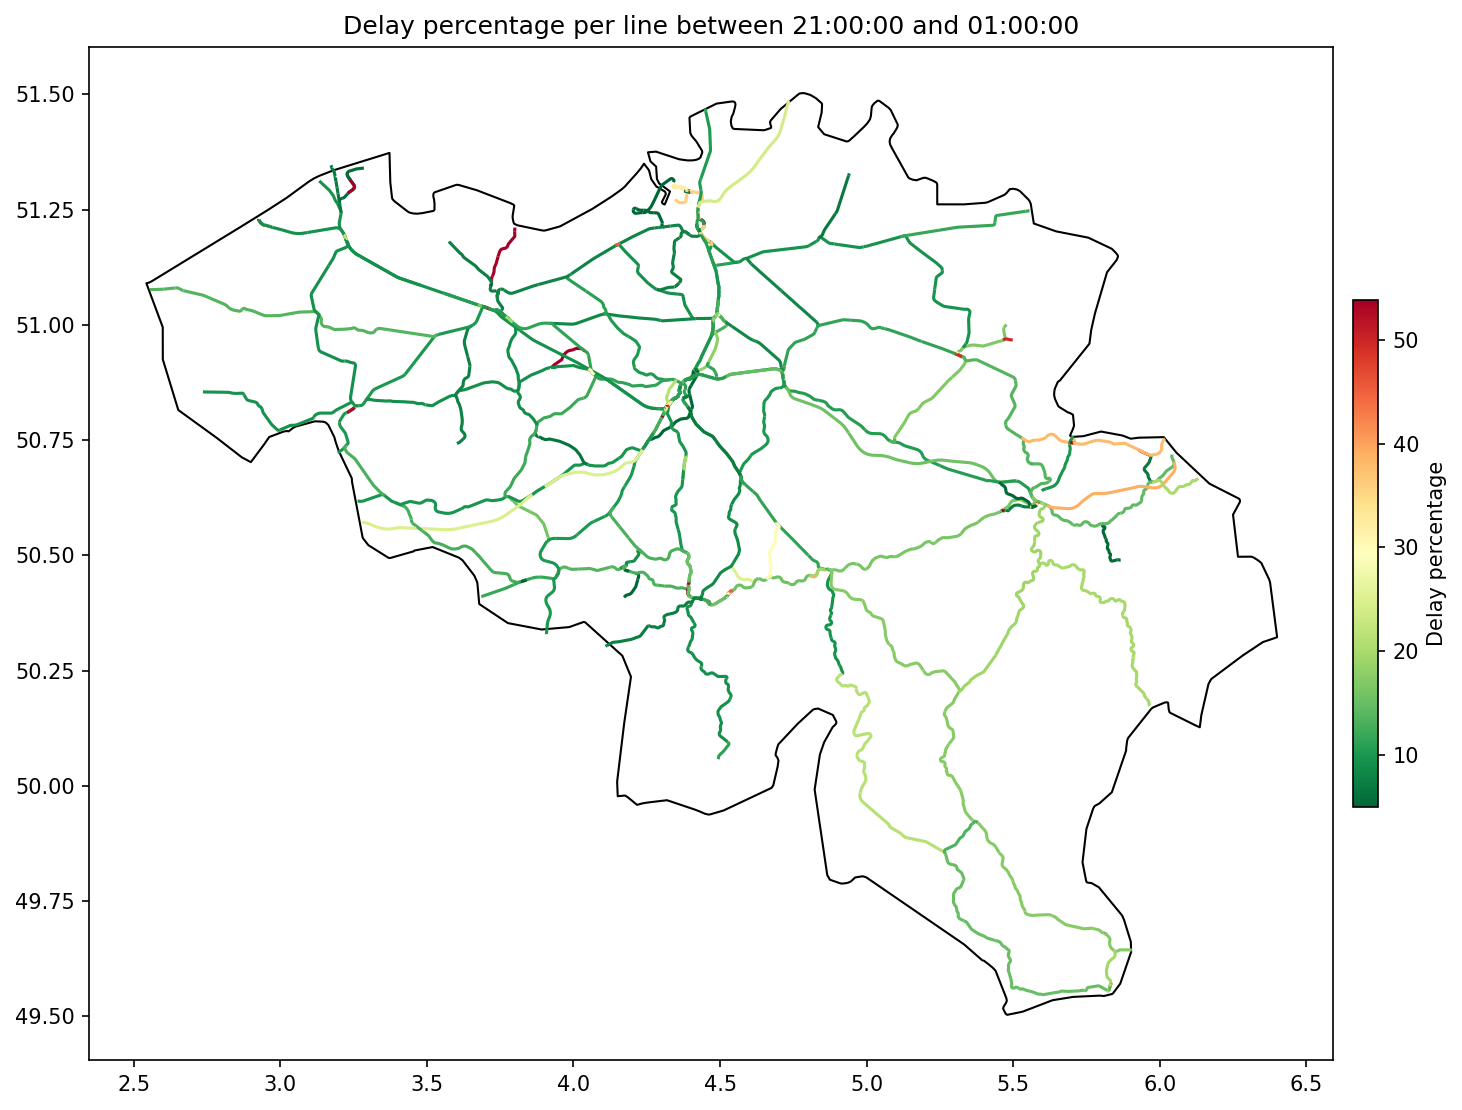

In [13]:
time_ranges = [
    ("06:00:00", "11:00:00"),
    ("11:00:00", "16:00:00"),
    ("16:00:00", "21:00:00"),
    ("21:00:00", "01:00:00"),
]

where_clause = ["td.planned_time_arrival"]

for start, end in time_ranges:
    analysis_query = f"""
        WITH delay_counts AS (
            SELECT
                line_number_departure,
                COUNT(*) as TOTAL_COUNT,
                SUM(CASE WHEN delay_arrival > 300 THEN 1 ELSE 0 END) AS
                    delayed_count,
                (SUM(CASE WHEN delay_arrival > 300 THEN 1 ELSE 0 END) *
                    100.0 / COUNT(*)) AS delay_percentage
            FROM
                train_data td
            JOIN
                type_day h on h.date = td.departure_date
            WHERE
                {
        "(td.planned_time_arrival BETWEEN '" + start + "' AND '" + end + "')"
        if start < end
        else "(td.planned_time_arrival >= '"
        + start
        + "' OR td.planned_time_arrival <= '"
        + end
        + "')"
    }
            GROUP BY
                line_number_departure
        )
        SELECT
            cd.line_number_departure,
            cd.delay_percentage,
            r.geom
        FROM
            delay_counts cd
        JOIN
            railway r ON cd.line_number_departure = r.line_number
    """

    delay_percentage = gpd.read_postgis(analysis_query, engine)

    fig, ax = plt.subplots(figsize=(13.33, 7.5), dpi=150)
    vmin, vmax = (
        delay_percentage["delay_percentage"].quantile(0.05),
        delay_percentage["delay_percentage"].quantile(0.95),
    )
    norm = Normalize(vmin=vmin, vmax=vmax)
    delay_percentage.plot(
        ax=ax,
        column="delay_percentage",
        legend=True,
        cmap="RdYlGn_r",
        legend_kwds={
            "label": "Delay percentage",
            "shrink": 0.5,  # Reduce the size of the legend bar
            "aspect": 20,  # Make the legend bar thinner
            "pad": 0.01,  # Reduce gap between plot and legend
        },
        vmin=vmin,
        vmax=vmax,
    )
    belgium.plot(ax=ax, edgecolor="black", facecolor="white", linewidth=1)
    plt.title(f"Delay percentage per line between {start} and {end}")
    plt.tight_layout()
    plt.show()